# Homework 04 - Evaluation

## Data Preparation
* Check if the missing values are presented in the features.
* If there are missing values:
    * For categorical features, replace them with 'NA'
    * For numerical features, replace with with 0.0
    
Split the data into 3 parts with these exact calls:

In [1]:
import pandas as pd

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [ ]:
# Check missing values
df.isna().sum()

,0
lead_source,148
industry,240
employment_status,194
location,208
annual_income,369
number_of_courses_viewed,0
interaction_count,0
lead_score,35
converted,0


In [5]:
# Handle categorical missing values
cat_feat = df.select_dtypes(exclude='number').columns.to_list()
df[cat_feat] = df[cat_feat].fillna('NA')

In [ ]:
# Handle numerical missing values
num_feat = df.select_dtypes(include='number').columns.to_list()
num_feat.remove('converted')
df[num_feat] = df[num_feat].fillna(0.0)

In [7]:
# Check missing values
df.isna().sum().T

,0
lead_source,0
industry,0
employment_status,0
location,0
annual_income,0
number_of_courses_viewed,0
interaction_count,0
lead_score,0
converted,0


In [8]:
# Split data into 3 parts
from sklearn.model_selection import train_test_split
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [9]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [10]:
from sklearn.feature_extraction import DictVectorizer
dv = DictVectorizer(sparse=False)

# Use ALL features (categorical + numerical); numerical values are kept as-is
features = cat_feat + num_feat

train_dict = df_train[features].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

val_dict = df_val[features].to_dict(orient='records')
X_val = dv.transform(val_dict)

# Question 1: ROC AUC feature importance
ROC AUC could also be used to evaluate feature importance of numerical variables.

Let's do that

* For each numerical variable, use it as score (aka prediction) and compute the AUC with the y variable as ground truth.
* Use the training dataset for that

If your AUC is < 0.5, invert this variable by putting "-" in front

(e.g. -df_train['balance'])

AUC can go below 0.5 if the variable is negatively correlated with the target variable. You can change the direction of the correlation by negating this variable - then negative correlation becomes positive.

Which numerical variable (among the following 4) has the highest AUC?

* `lead_score`
* `number_of_courses_viewed`
* `interaction_count`
* `annual_income`

In [11]:
from sklearn.metrics import roc_auc_score
auc_scores = {}
for col in num_feat:
    score = roc_auc_score(y_train, df_train[col])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[col])
    auc_scores[col] = score
    print(f'{col}: {score:.4f}')

annual_income: 0.6082
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
lead_score: 0.7882


answer = `lead_score: 0.7882`

# Question 2: Training the model
What's the AUC of this model on the validation dataset? (round to 3 digits)


In [12]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [ ]:
y_pred_prob = model.predict_proba(X_val)

In [14]:
val_roc_score = roc_auc_score(y_val, y_pred_prob[:,1])
print(f'{val_roc_score:.3f}')

0.732


answer = `0.732`

# Question 3: Precision and Recall
* Evaluate the model on all thresholds from 0.0 to 1.0 with step 0.01
* For each threshold, compute precision and recall
* Plot them

At which threshold precision and recall curves intersect? Ignore thresholds at which both metrics are zero, and choose the threshold with the smallest absolute difference between precision and recall.

* 0.43
* 0.63
* 0.73
* 0.83

In [15]:
import numpy as np
import matplotlib.pyplot as plt

y_score = y_pred_prob[:, 1]
thresholds = np.arange(0.0, 1.01, 0.01)

def confusion_counts(y_true, y_score, t):
    pred = (y_score >= t)
    tp = int(((pred) & (y_true == 1)).sum())
    fp = int(((pred) & (y_true == 0)).sum())
    fn = int(((~pred) & (y_true == 1)).sum())
    tn = int(((~pred) & (y_true == 0)).sum())
    return tp, fp, fn, tn

rows = []
for t in thresholds:
    tp, fp, fn, tn = confusion_counts(y_val, y_score, t)
    p = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    r = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    rows.append({'threshold': round(t, 2), 'precision': p, 'recall': r, 'f1': f1})

df_scores = pd.DataFrame(rows)
df_scores.head()

,threshold,precision,recall,f1
0,0.00,0.586,1.0,0.738966
1,0.01,0.586,1.0,0.738966
2,0.02,0.586,1.0,0.738966
3,0.03,0.586,1.0,0.738966
4,0.04,0.586,1.0,0.738966


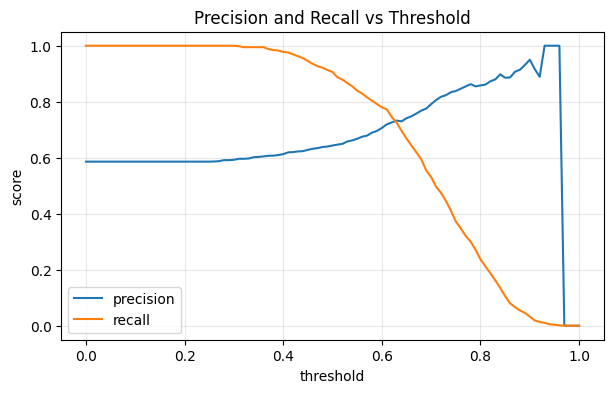

In [16]:
plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.precision, label='precision')
plt.plot(df_scores.threshold, df_scores.recall, label='recall')
plt.xlabel('threshold')
plt.ylabel('score')
plt.title('Precision and Recall vs Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [ ]:
# Ignore thresholds where both precision and recall are zero
nonzero = df_scores[(df_scores.precision > 0) | (df_scores.recall > 0)].copy()
nonzero['abs_diff'] = (nonzero.precision - nonzero.recall).abs()
nonzero.sort_values('abs_diff').head(3)

,threshold,precision,recall,f1,abs_diff
63,0.63,0.732759,0.725256,0.728988,0.007503
62,0.62,0.725914,0.745734,0.735690,0.019820
64,0.64,0.729875,0.696246,0.712664,0.033629


answer = `0.63`

# Question 4: F1 score
$$F_1 = 2 \cdot \cfrac{P \cdot R}{P + R}$$

Where $P$ is precision and $R$ is recall.

Let's compute F1 for all thresholds from 0.0 to 1.0 with increment 0.01

At which threshold F1 is maximal?

* 0.21
* 0.41
* 0.61
* 0.81

Max F1 = 0.7576 at threshold = 0.41


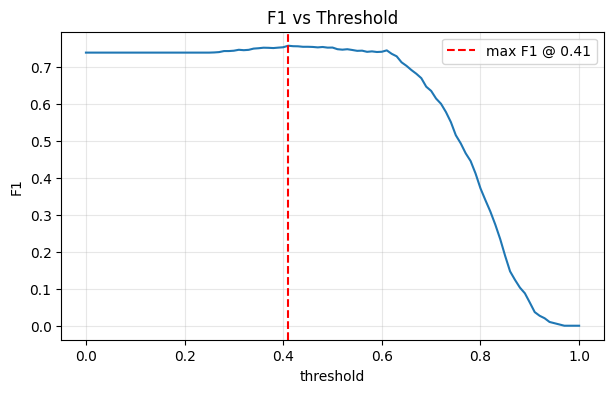

In [18]:
best = df_scores.loc[df_scores.f1.idxmax()]
print(f"Max F1 = {best.f1:.4f} at threshold = {best.threshold:.2f}")

plt.figure(figsize=(7, 4))
plt.plot(df_scores.threshold, df_scores.f1)
plt.axvline(best.threshold, color='red', linestyle='--', label=f'max F1 @ {best.threshold:.2f}')
plt.xlabel('threshold')
plt.ylabel('F1')
plt.title('F1 vs Threshold')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

answer = `0.41`

# Question 5: 5-Fold CV
Use the `KFold` class from Scikit-Learn to evaluate our model on 5 different folds:

`KFold(n_splits=5, shuffle=True, random_state=1)`

* Iterate over different folds of `df_full_train`
* Split the data into train and validation
* Train the model on train with these parameters: `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)`
* Use AUC to evaluate the model on validation

How large is standard deviation of the scores across different folds?

* 0.001
* 0.007
* 0.013
* 0.060

In [19]:
from sklearn.model_selection import KFold

def train(df_tr, y_tr, C=1.0):
    dicts = df_tr[features].to_dict(orient='records')
    dv = DictVectorizer(sparse=False)
    X = dv.fit_transform(dicts)
    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X, y_tr)
    return dv, model

def predict(df_x, dv, model):
    dicts = df_x[features].to_dict(orient='records')
    X = dv.transform(dicts)
    return model.predict_proba(X)[:, 1]

def cross_validate(C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    scores = []
    for train_idx, val_idx in kfold.split(df_full_train):
        d_tr = df_full_train.iloc[train_idx]
        d_va = df_full_train.iloc[val_idx]
        dv_, m_ = train(d_tr, d_tr.converted.values, C=C)
        y_hat = predict(d_va, dv_, m_)
        scores.append(roc_auc_score(d_va.converted.values, y_hat))
    return scores

scores = cross_validate(C=1.0)
print('AUC per fold:', np.round(scores, 4))
print(f'mean = {np.mean(scores):.3f}, std = {np.std(scores):.3f}')

AUC per fold: [0.7306 0.7296 0.7363 0.7412 0.7209]
mean = 0.732, std = 0.007


answer = `0.007`

# Question 6: Hyperparameter Tuning
Now let's use 5-Fold cross-validation to find the best parameter `C`

* Iterate over the following `C` values: `[0.000001, 0.001, 1]`
* Initialize `KFold` with the same parameters as previously
* Use these parameters for the model: `LogisticRegression(solver='liblinear', C=C, max_iter=1000)`
* Compute the mean ROC AUC as well as the std (round the mean and std to 3 decimal digits).

Which `C` leads to the best mean ROC AUC?

* 0.000001
* 0.001
* 1

If you have ties, select the score with the lowest std. If you still have ties, select the smallest `C`.

In [20]:
results = []
for C in [0.000001, 0.001, 1]:
    s = cross_validate(C=C)
    results.append({'C': C, 'mean': round(np.mean(s), 3), 'std': round(np.std(s), 3)})

df_cv = pd.DataFrame(results)
print(df_cv.to_string(index=False))

# best: highest mean, tie -> lowest std, tie -> smallest C
best_row = df_cv.sort_values(['mean', 'std', 'C'], ascending=[False, True, True]).iloc[0]
print(f"\nBest C = {best_row.C}")

       C  mean   std
0.000001 0.617 0.019
0.001000 0.749 0.010
1.000000 0.732 0.007

Best C = 0.001


answer = `0.001`